# 08 · Preference tuning and RL with TRL: DPO and GRPO

SFT (notebook 07) imitates reference answers. The next two post-training stages learn from **comparisons** and from **rewards**:

**DPO** (Direct Preference Optimization) learns from pairs (prompt, *chosen*, *rejected*). It needs no reward model and no RL loop: it directly raises the chosen answer's log-probability relative to the rejected one, measured against a frozen **reference** model (the SFT model):
$$\mathcal{L}_{\text{DPO}} = -\log\sigma\Big(\beta\Big[\underbrace{\log\tfrac{\pi(y_w|x)}{\pi_{\text{ref}}(y_w|x)}}_{\text{implicit reward of chosen}} - \underbrace{\log\tfrac{\pi(y_l|x)}{\pi_{\text{ref}}(y_l|x)}}_{\text{implicit reward of rejected}}\Big]\Big)$$
β controls how far the policy may drift from the reference.

**GRPO** (Group Relative Policy Optimization, DeepSeekMath / DeepSeek-R1) is RL with a **verifier**: for each prompt, sample a *group* of G answers, score each with a reward function (plain code), and use the group-normalized reward $A_i = (r_i - \bar r)/\sigma_r$ as the advantage. Answers better than their siblings become more likely, worse ones less likely. No critic network; a KL term keeps the policy near the reference.

**Plan**
1. Start from a *partially* trained SFT model on notebook 07's booking task (so there is room to improve).
2. DPO with `trl.DPOTrainer`, and its failure mode: **likelihood displacement**. Then the fix: DPO + an SFT (NLL) term.
3. GRPO with `trl.GRPOTrainer` on arithmetic, with a **sparse** (exact) vs a **dense** (partial-credit) reward.
4. Held-out evaluation of everything, and an honest discussion.

## Background: from RLHF to direct preference optimization and verifiable rewards

### The limits of imitation

SFT maximizes the likelihood of demonstrations. That has two blind spots. It gives no signal about *how bad* a wrong answer is (every token of every demonstration counts the same), and it only shows the model good behaviour in states taken from the data, never in the states its own mistakes lead to. For many goals it is also easier for people to **compare** two answers than to **write** the ideal one: which reply is more helpful, which summary is more faithful, which proof is correct. Post-training after SFT turns those judgements into a training signal.

### Classic RLHF: reward model plus PPO

The pipeline popularized by Christiano et al. (2017), Stiennon et al. (2020) and InstructGPT (Ouyang et al., 2022) has three stages:

```
1. SFT on demonstrations                         -> pi_ref
2. fit a reward model r_phi on human comparisons  -> r_phi(x, y)
3. RL: maximize r_phi with PPO, staying close to pi_ref
```

**Step 2: the Bradley-Terry model.** Preferences are modelled as noisy comparisons of a latent score. The probability that a person prefers $y_w$ (winner) over $y_l$ (loser) for prompt $x$ is
$$P(y_w \succ y_l \mid x) = \sigma\big(r(x, y_w) - r(x, y_l)\big) = \frac{1}{1 + e^{-(r(x,y_w) - r(x,y_l))}}$$
This is the model Bradley and Terry (1952) proposed for ranking from paired comparisons; Elo ratings in chess rest on the same idea. A reward model $r_\phi$ (usually the SFT model with a scalar head) is fitted by maximum likelihood: $\mathcal{L}_{\text{RM}} = -\mathbb{E}\,\log\sigma\big(r_\phi(x,y_w) - r_\phi(x,y_l)\big)$. Only *differences* of rewards are identified, so the reward has an arbitrary offset per prompt.

**Step 3: the KL-regularized objective.** The policy is trained to maximize
$$\max_{\pi}\; \mathbb{E}_{x\sim\mathcal{D},\,y\sim\pi(\cdot|x)}\big[r_\phi(x,y)\big] \;-\; \beta\,\mathrm{KL}\big(\pi(\cdot|x)\,\|\,\pi_{\text{ref}}(\cdot|x)\big)$$
The KL term matters as much as the reward. The reward model is only accurate near the data it was trained on; without the leash, the policy finds outputs the reward model scores highly for the wrong reasons (**reward hacking**, or *over-optimization*: Gao et al., 2023, *Scaling Laws for Reward Model Overoptimization*, measured how the true quality first rises and then falls as the policy optimizes a proxy reward harder). The KL also keeps the language fluent.

**Why PPO was hard to live with.** PPO (Schulman et al., 2017) is an actor-critic method. For LLMs it needs four models at once: the policy, the frozen reference, the reward model, and a **value network** (critic) of similar size that estimates expected future reward per token to compute advantages. It samples from the policy in the loop, which is slow, and it has many sensitive hyperparameters (clip range, value-loss weight, GAE $\lambda$, KL coefficient). It works, as InstructGPT and many later models show, but it is expensive and fragile, which pushed the field toward two simplifications.

### DPO: the reward model is hidden inside the policy

Rafailov et al. (2023) noticed that the KL-regularized objective has a closed-form optimum for any reward $r$:
$$\pi^*(y \mid x) = \frac{1}{Z(x)}\,\pi_{\text{ref}}(y \mid x)\,\exp\!\Big(\frac{1}{\beta} r(x,y)\Big), \qquad Z(x) = \sum_y \pi_{\text{ref}}(y\mid x)\exp\!\Big(\frac{1}{\beta} r(x,y)\Big)$$
$Z(x)$ sums over every possible answer, so this cannot be computed directly. But it can be **inverted**: take logs and solve for the reward,
$$r(x,y) = \beta \log\frac{\pi^*(y\mid x)}{\pi_{\text{ref}}(y\mid x)} + \beta \log Z(x)$$
Every reward corresponds to a policy and vice versa. Now substitute this into the Bradley-Terry likelihood. Both answers share the same prompt, so the intractable $\beta\log Z(x)$ appears in both rewards and **cancels in the difference**. What is left depends only on the policy and the reference, and maximizing the preference likelihood over policies gives exactly the DPO loss written above:
$$\mathcal{L}_{\text{DPO}} = -\,\mathbb{E}\,\log\sigma\big(\hat r(x,y_w) - \hat r(x,y_l)\big), \qquad \hat r(x,y) = \beta\log\frac{\pi_\theta(y\mid x)}{\pi_{\text{ref}}(y\mid x)}$$
The policy *is* the reward model; $\hat r$ is called the **implicit reward**. Training is a classification loss on pairs: no sampling, no value network, no separate reward model. Only the policy and a frozen reference are needed, and with LoRA the reference is the same network with the adapter switched off.

**What the gradient does.** Differentiating gives
$$\nabla_\theta \mathcal{L}_{\text{DPO}} = -\beta\,\mathbb{E}\Big[\underbrace{\sigma\big(\hat r(x,y_l) - \hat r(x,y_w)\big)}_{\text{large when the pair is ranked wrongly}}\big(\nabla_\theta \log\pi_\theta(y_w\mid x) - \nabla_\theta \log\pi_\theta(y_l\mid x)\big)\Big]$$
Pairs the model already ranks correctly get a small weight; pairs it gets wrong get a large one. And the update only constrains the *difference* of the two log-probabilities, which is the root of the failure studied in section 3.

**The role of $\beta$.** Small $\beta$ means a weak leash: the policy may move far from the reference to fit the preferences. Large $\beta$ keeps it close. Typical values are 0.01 to 0.5; 0.1 is the common default.

### What DPO gives up, and its variants

DPO optimizes the same objective as RLHF only under assumptions that rarely hold exactly: the preference data must cover the answers the policy will produce, and the Bradley-Terry model must be right. In practice:

- **It is offline.** It learns from a fixed set of pairs and never explores. If the pairs come from another model, the policy is pushed around in regions it does not visit. Iterative or "online" DPO (regenerate pairs from the current policy, label, repeat) closes much of the gap.
- **It can overfit deterministic preferences.** When one answer always wins, the Bradley-Terry likelihood is maximized by an infinite reward gap, and the KL regularization is not enforced by the loss on finite data (Azar et al., 2023, who proposed IPO with a squared loss on the margin instead).
- **It can exploit length** and other surface features that correlate with preference.
- **Chosen likelihood can fall** (likelihood displacement, section 3).

| method | data | idea | reference |
|---|---|---|---|
| DPO | pairs | Bradley-Terry on implicit rewards | Rafailov et al., 2023 |
| IPO | pairs | regress the margin to a fixed target, avoids overfitting | Azar et al., 2023 |
| KTO | single answers labelled good / bad | prospect-theory utility, no pairs needed | Ethayarajh et al., 2024 |
| ORPO | pairs | odds-ratio penalty added to SFT, no reference model | Hong et al., 2024 |
| SimPO | pairs | length-normalized log-probability as reward, no reference model | Meng et al., 2024 |
| DPO + NLL / RPO | pairs | add the SFT loss on the chosen answer | Pang et al., 2024; Liu et al., 2024 |

Whether DPO matches well-tuned PPO is **debated**. Xu et al. (2024, *Is DPO Superior to PPO for LLM Alignment? A Comprehensive Study*) found PPO ahead on harder tasks such as code when tuned carefully; DPO's popularity in open models comes mostly from its simplicity and stability, not from a proven quality advantage.

### RL with verifiable rewards and GRPO

For math, code and other tasks with a checkable answer, the reward model can be replaced by a program: a unit test, a numeric comparison, a JSON schema. This setting is called **RL with verifiable rewards (RLVR)** (the term was popularized by the Tülu 3 report, Lambert et al., 2024). A program cannot be flattered the way a learned reward model can, which removes one source of reward hacking (but not all: a lenient checker can still be gamed).

**The policy gradient.** Treat a whole answer $y$ as one action with reward $r(x,y)$. The REINFORCE identity gives
$$\nabla_\theta\, \mathbb{E}_{y\sim\pi_\theta}[r] = \mathbb{E}_{y\sim\pi_\theta}\big[(r - b)\,\nabla_\theta \log\pi_\theta(y\mid x)\big]$$
for any baseline $b$ that does not depend on $y$. The baseline does not change the expected gradient but can reduce its variance enormously; the best simple choice is the expected reward of the prompt. PPO learns that baseline with a value network. **GRPO** (Shao et al., 2024, *DeepSeekMath*) estimates it instead from a *group* of $G$ samples for the same prompt:
$$A_i = \frac{r_i - \operatorname{mean}(r_1,\dots,r_G)}{\operatorname{std}(r_1,\dots,r_G)}$$
and applies the same advantage to every token of answer $i$. The full objective keeps PPO's clipped importance ratio and adds a KL penalty to the reference:
$$\mathcal{J}(\theta) = \mathbb{E}\Bigg[\frac{1}{G}\sum_{i=1}^{G}\frac{1}{|y_i|}\sum_{t=1}^{|y_i|}\Big(\min\big(\rho_{i,t}A_i,\; \operatorname{clip}(\rho_{i,t}, 1-\epsilon, 1+\epsilon)A_i\big) - \beta\, \mathbb{D}_{\text{KL}}^{(i,t)}\Big)\Bigg],\quad \rho_{i,t} = \frac{\pi_\theta(y_{i,t}\mid x, y_{i,<t})}{\pi_{\theta_{\text{old}}}(y_{i,t}\mid x, y_{i,<t})}$$
The per-token KL is estimated with the low-variance, always non-negative estimator $\frac{\pi_{\text{ref}}}{\pi_\theta} - \log\frac{\pi_{\text{ref}}}{\pi_\theta} - 1$. When each batch of samples is used for a single gradient step, $\rho = 1$ and the clipping never activates; the objective reduces to a group-baselined policy gradient with a KL term.

**Consequences of the group baseline.**
- No critic: one fewer large model in memory, no value-loss tuning.
- A group in which all answers get the same reward has zero advantage everywhere and contributes no gradient. Prompts must be neither too easy nor too hard for the current policy; this is why the fraction of zero-variance groups is a key diagnostic (and why DAPO, Yu et al., 2025, filters such groups out, "dynamic sampling").
- The normalization introduces biases that later work examined. Liu et al. (2025, *Understanding R1-Zero-Like Training: A Critical Perspective*, "Dr. GRPO") argued that dividing by $|y_i|$ favours long wrong answers and dividing by the std over-weights prompts whose samples are nearly all right or nearly all wrong (small std), and proposed dropping both. TRL exposes these choices as `GRPOConfig(loss_type=..., scale_rewards=...)`.

The DeepSeek-R1 report (DeepSeek-AI, 2025) showed with its R1-Zero model that GRPO with simple correctness and format rewards, applied directly to a strong base model, produces long chain-of-thought reasoning without any supervised reasoning traces (the released R1 adds a small SFT "cold start" and further stages for readability). How much RLVR *creates* new abilities versus *sharpens* ones the base model can already sample is an open question: Yue et al. (2025, *Does Reinforcement Learning Really Incentivize Reasoning Capacity in LLMs Beyond the Base Model?*) found that at large sample counts (pass@k with big k) base models often solve as many problems as their RL-trained versions.

### The three approaches side by side

| | RLHF with PPO | DPO | GRPO (RLVR) |
|---|---|---|---|
| signal | learned reward model from comparisons | comparisons, used directly | a program that checks the answer |
| models in memory | policy, reference, reward, value | policy, reference | policy, reference (none if $\beta = 0$) |
| sampling during training | yes | no | yes, $G$ samples per prompt |
| online / exploration | yes | no (unless iterated) | yes |
| main cost | compute, tuning effort | preference data collection | sampling time |
| typical failure | reward hacking, instability | overfitting, likelihood displacement | reward hacking of a lenient checker, zero-variance groups |
| where it is used today | large labs' chat alignment | open-model alignment, style and safety tuning | reasoning: math, code, tool use |

### Key papers

- Christiano et al., 2017. *Deep Reinforcement Learning from Human Preferences.*
- Schulman et al., 2017. *Proximal Policy Optimization Algorithms.*
- Ouyang et al., 2022. *Training Language Models to Follow Instructions with Human Feedback* (InstructGPT).
- Rafailov et al., 2023. *Direct Preference Optimization: Your Language Model is Secretly a Reward Model.*
- Azar et al., 2023. *A General Theoretical Paradigm to Understand Learning from Human Preferences* (IPO).
- Shao et al., 2024. *DeepSeekMath: Pushing the Limits of Mathematical Reasoning in Open Language Models* (GRPO).
- DeepSeek-AI, 2025. *DeepSeek-R1: Incentivizing Reasoning Capability in LLMs via Reinforcement Learning.*
- Razin et al., 2024. *Unintentional Unalignment: Likelihood Displacement in Direct Preference Optimization.*

In [1]:
import os, sys, json, time, random, re, gc, copy, tempfile, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import transformers, peft, trl, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
transformers.utils.logging.set_verbosity_error()   # keep the notebook output to what we print ourselves
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
import huggingface_hub; huggingface_hub.utils.logging.set_verbosity_error()
set_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = device == "cuda" and torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if BF16 else torch.float32
# We share the GPU with Ollama, so we give this notebook a fixed VRAM budget. Going over it raises an
# out-of-memory error right away instead of silently spilling into (very slow) system RAM.
VRAM_BUDGET_GB = float(os.environ.get("VRAM_BUDGET_GB", 1.5))
if device == "cuda":
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    torch.cuda.set_per_process_memory_fraction(min(1.0, VRAM_BUDGET_GB / total))
    print(f"GPU: {torch.cuda.get_device_name(0)} ({total:.1f} GB), bf16: {BF16}, budget for this notebook: {VRAM_BUDGET_GB} GB")
else:
    print("No GPU found: running on CPU (expect it to be much slower)")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__, "| trl", trl.__version__)

def from_pretrained(cls, name, **kw):
    """Load from the local Hugging Face cache when the model is there, and download it otherwise."""
    try:
        return cls.from_pretrained(name, local_files_only=True, **kw)
    except OSError:
        return cls.from_pretrained(name, **kw)

def free():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

def reset_peak():
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()

def peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")

GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.4 GB), bf16: True, budget for this notebook: 1.5 GB
torch 2.14.1+cu130 | transformers 5.22.2 | peft 0.21.2 | trl 1.17.1


## 1. The starting point: a partially trained SFT model

Same task, data and metrics as notebook 07: extract a restaurant booking as strict JSON, 300 labelled examples, 40 held-out requests with unseen names and restaurants.

In [2]:
TRAIN_NAMES = ["Ana", "Luis", "Marta", "Pablo", "Sofia", "Diego", "Elena", "Jorge", "Lucia", "Carlos", "Irene", "Tomas",
               "Nuria", "Raul", "Clara", "Hugo", "Paula", "Adrian", "Sara", "Mario", "Laura", "Ivan", "Julia", "Victor"]
TEST_NAMES = ["Beatriz", "Oscar", "Alba", "Marcos", "Noelia", "Gonzalo", "Rocio", "Felipe", "Ines", "Samuel"]
TRAIN_PLACES = ["Casa Pepe", "La Tagliatella", "Sushi Zen", "El Faro", "Burger Hub", "Taco Loco", "Le Petit Bistro",
                "Green Garden", "La Brasa", "Mar Azul", "Pizza Napoli", "The Golden Duck", "Curry House", "El Rincon"]
TEST_PLACES = ["Asador Toro", "Bella Vista", "Noodle Bar", "Casa Lola", "The Oak Room", "Kebab Palace", "Ramen Ya"]
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
NUM_WORDS = {2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine", 10: "ten"}
TEMPLATES = [
    "Hi, I'd like to book a table for {people} at {place} on {day} at {time}. The name is {name}.",
    "Can you reserve {place} for {people} people this {day} at {time}? It's under {name}.",
    "{name} here. Table for {people} at {place}, {day}, {time} please.",
    "Please make a reservation at {place}: {people} guests, {day} {time}, name {name}.",
    "We are {people}. Could we get a table at {place} on {day} around {time}? Booking for {name}.",
    "Book {place} for {name}, party of {people}, {day} at {time}.",
]
SYSTEM = "Extract the booking as JSON: name, restaurant, people (int), day (lowercase), time (24h HH:MM)."
FIELDS = ["name", "restaurant", "people", "day", "time"]

def time_text(h, m, rng):
    """The same time written the way people write it: 8pm, 8:30 pm, 20:30 or 8 in the evening."""
    h12 = h - 12 if h > 12 else h
    return [f"{h12}{':%02d' % m if m else ''}pm", f"{h12}:{m:02d} pm", f"{h:02d}:{m:02d}",
            f"{h12}{':%02d' % m if m else ''} in the evening"][rng.randrange(4)]

def make_booking(rng, names, places):
    people, h, m = rng.randint(2, 10), rng.randint(13, 22), rng.choice([0, 0, 15, 30, 45])
    target = {"name": rng.choice(names), "restaurant": rng.choice(places), "people": people,
              "day": rng.choice(DAYS), "time": f"{h:02d}:{m:02d}"}
    text = rng.choice(TEMPLATES).format(
        people=NUM_WORDS[people] if rng.random() < 0.4 else str(people), place=target["restaurant"],
        day=target["day"].capitalize() if rng.random() < 0.7 else target["day"], time=time_text(h, m, rng), name=target["name"])
    return text, target

def booking_examples(n, seed, split="train"):
    rng = random.Random(seed)
    names, places = (TRAIN_NAMES, TRAIN_PLACES) if split == "train" else (TEST_NAMES, TEST_PLACES)
    return [make_booking(rng, names, places) for _ in range(n)]

def to_prompt_completion(text, target, system=SYSTEM):
    """TRL's conversational prompt-completion format: the loss will only cover the completion."""
    return {"prompt": [{"role": "system", "content": system}, {"role": "user", "content": text}],
            "completion": [{"role": "assistant", "content": json.dumps(target)}]}

train_pairs = booking_examples(300, seed=0)                 # our labelled budget
test_pairs = booking_examples(40, seed=1, split="test")     # held out: unseen names and restaurants
train_rows = [to_prompt_completion(x, y) for x, y in train_pairs]
for x, y in train_pairs[:3]:
    print(x, "\n   ->", json.dumps(y))

Please make a reservation at La Brasa: 8 guests, thursday 7 in the evening, name Lucia. 
   -> {"name": "Lucia", "restaurant": "La Brasa", "people": 8, "day": "thursday", "time": "19:00"}
Can you reserve Sushi Zen for 7 people this Wednesday at 22:00? It's under Paula. 
   -> {"name": "Paula", "restaurant": "Sushi Zen", "people": 7, "day": "wednesday", "time": "22:00"}
Hi, I'd like to book a table for 10 at La Tagliatella on Saturday at 10 in the evening. The name is Carlos. 
   -> {"name": "Carlos", "restaurant": "La Tagliatella", "people": 10, "day": "saturday", "time": "22:00"}


In [3]:
def parse_json(reply):
    m = re.search(r"\{.*\}", reply, re.S)
    try:
        obj = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None

def score(replies, pairs=None):
    pairs = pairs or test_pairs
    objs = [parse_json(r) for r in replies]
    return {"valid": np.mean([o is not None for o in objs]),
            "exact": np.mean([o == y for o, (_, y) in zip(objs, pairs)]),
            "fields": np.mean([np.mean([(o or {}).get(k) == v for k, v in y.items()]) for o, (_, y) in zip(objs, pairs)]),
            "time": np.mean([(o or {}).get("time") == y["time"] for o, (_, y) in zip(objs, pairs)])}

@torch.no_grad()
def generate(model, tok, prompts, max_new_tokens=64, batch_size=20, skip_special_tokens=True):
    """Greedy replies for a list of chat prompts, in batches (left padding so every prompt ends at the same position)."""
    model.eval(); tok.padding_side = "left"; out = []
    for i in range(0, len(prompts), batch_size):
        enc = tok.apply_chat_template(prompts[i:i + batch_size], add_generation_prompt=True, return_tensors="pt",
                                      return_dict=True, padding=True).to(model.device)
        ids = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        out += tok.batch_decode(ids[:, enc["input_ids"].shape[1]:], skip_special_tokens=skip_special_tokens)
    return out

RESULTS = {}      # name -> metrics, filled by evaluate()
def evaluate(model, tok, name, prompts=None, show=0):
    replies = generate(model, tok, prompts or [to_prompt_completion(x, y)["prompt"] for x, y in test_pairs])
    RESULTS[name] = s = score(replies)
    print(f"{name:34s} valid {100*s['valid']:5.1f}% | exact {100*s['exact']:5.1f}% | fields {100*s['fields']:5.1f}% | time {100*s['time']:5.1f}%")
    for r in replies[:show]:
        print("    ", r[:150].replace("\n", " "))
    return replies

In [4]:
from datasets import Dataset
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer, DPOConfig, DPOTrainer, GRPOConfig, GRPOTrainer
from transformers import PrinterCallback

MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"
OUT = os.path.join(tempfile.gettempdir(), "llm_edu_08")
tok = from_pretrained(AutoTokenizer, MODEL)
RUNS = {}

def lora(r=16):
    return LoraConfig(r=r, lora_alpha=2 * r, target_modules="all-linear", task_type="CAUSAL_LM")

def common(micro_batch, accum, logging_steps=2):
    """The training arguments every trainer below shares."""
    return dict(output_dir=OUT, per_device_train_batch_size=micro_batch, gradient_accumulation_steps=accum, bf16=BF16,
                gradient_checkpointing=True, logging_steps=logging_steps, save_strategy="no", report_to="none",
                disable_tqdm=True, seed=0)

def run(trainer, name):
    """Train, record time / peak VRAM / logs, and return the merged model."""
    trainer.remove_callback(PrinterCallback)
    reset_peak(); t0 = time.time()
    trainer.train()
    RUNS[name] = {"time": time.time() - t0, "peak": peak_gb(), "logs": trainer.state.log_history}
    print(f"{name}: {trainer.state.global_step} steps, {RUNS[name]['time']:.0f} s, peak VRAM {RUNS[name]['peak']:.2f} GB")
    return trainer.model.merge_and_unload()

cfg = SFTConfig(num_train_epochs=2, learning_rate=1e-3, lr_scheduler_type="cosine", warmup_steps=5, max_length=256, **common(8, 2))
sft_model = run(SFTTrainer(model=from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), args=cfg,
                           train_dataset=Dataset.from_list(train_rows), processing_class=tok, peft_config=lora()), "SFT (LoRA)")
sft_replies = evaluate(sft_model, tok, "SFT", show=3)
SFT_STATE = {k: v.detach().cpu().clone() for k, v in sft_model.state_dict().items()}   # a CPU snapshot, to restart every method from the same SFT model

SFT (LoRA): 38 steps, 43 s, peak VRAM 1.40 GB


SFT                                valid 100.0% | exact  30.0% | fields  86.0% | time  30.0%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "10:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "18:00"}
     {"name": "Beatriz", "restaurant": "Asador Toro", "people": 3, "day": "saturday", "time": "19:00"}


As in notebook 07, the SFT model always writes valid JSON and gets names, places, party sizes and days right. Most errors are the 12-hour → 24-hour conversion (for example writing `10:00` for "10 pm"). That is a clear target for preference tuning.

## 2. Preference pairs

DPO needs (prompt, chosen, rejected). The best rejected answers are the model's **own** mistakes: they show the model exactly what it currently does wrong (this is "on-policy" preference data). So we run the SFT model on 400 new training requests and check its answers. Where it is wrong, its answer becomes *rejected* and the right one *chosen*. Where it is right, we build a rejected answer with one realistic mistake (mostly the same time error). In a real project a human, a verifier or an LLM judge decides which answer is better; here the generator knows the truth.

**Why the source of the pairs matters.** The DPO gradient only touches the sequences that appear in the pairs. If the rejected answers are mistakes the model would never make, pushing them down changes nothing the model actually does; if the chosen answers are far from what the model would write (say, from a much stronger model), the update has to drag the policy toward a distribution it does not cover, and the implicit reward is estimated where the policy has almost no mass. On-policy pairs put the gradient exactly where the model's behaviour is. This is also why iterated DPO (sample, label, train, repeat) behaves more like online RL than a single offline pass.

**The labelling source sets the ceiling.** Human comparisons are the classic source; "RLAIF" uses an LLM judge instead (Bai et al., 2022, *Constitutional AI*; Lee et al., 2023, *RLAIF*), and for tasks with a checker the verifier can label the pairs. Whatever labels the pairs defines what "better" means, including its biases (judges tend to prefer longer answers, for example).

In [5]:
def corrupt(target, rng):
    """A plausible wrong answer that differs from the right one in one field."""
    bad = dict(target)
    kind = rng.choice(["time12", "time12", "people_str", "day_cap", "name"])
    if kind == "time12":
        h, m = target["time"].split(":"); bad["time"] = f"{int(h) - 12:02d}:{m}"
    elif kind == "people_str":
        bad["people"] = str(target["people"])
    elif kind == "day_cap":
        bad["day"] = target["day"].capitalize()
    else:
        bad["name"] = rng.choice([n for n in TRAIN_NAMES if n != target["name"]])
    return bad

pref_pairs = booking_examples(400, seed=5)
own = generate(sft_model, tok, [to_prompt_completion(x, y)["prompt"] for x, y in pref_pairs])
rng = random.Random(0); pref_rows = []; n_own = 0
for (x, y), reply in zip(pref_pairs, own):
    obj = parse_json(reply)
    if obj is not None and obj != y:
        rejected = obj; n_own += 1                  # the model's own mistake
    else:
        rejected = corrupt(y, rng)
    pref_rows.append({"prompt": to_prompt_completion(x, y)["prompt"],
                      "chosen": [{"role": "assistant", "content": json.dumps(y)}],
                      "rejected": [{"role": "assistant", "content": json.dumps(rejected)}]})
print(f"{len(pref_rows)} pairs, {n_own} of them with the SFT model's own mistake as the rejected answer")
print("chosen:  ", pref_rows[0]["chosen"][0]["content"]); print("rejected:", pref_rows[0]["rejected"][0]["content"])

400 pairs, 256 of them with the SFT model's own mistake as the rejected answer
chosen:   {"name": "Ana", "restaurant": "El Rincon", "people": 6, "day": "thursday", "time": "18:45"}
rejected: {"name": "Ana", "restaurant": "El Rincon", "people": 6, "day": "Thursday", "time": "18:45"}


## 3. DPO with TRL

`DPOTrainer` takes the policy, a preference dataset and a `DPOConfig`. With a `peft_config`, we train a fresh LoRA adapter on top of the SFT model, and the reference model comes for free: it is the same network with the adapter switched off. The trainer logs what we need to diagnose DPO:
- `rewards/accuracies`: how often the implicit reward prefers chosen over rejected;
- `rewards/margins`: the mean gap between the two implicit rewards;
- `logps/chosen`, `logps/rejected`: the policy's log-probability of each answer.

How to read them against the theory: the implicit reward is $\hat r = \beta\,(\log\pi_\theta - \log\pi_{\text{ref}})$ summed over the answer's tokens, so at step 0 (adapter at zero, policy = reference) both rewards are exactly 0, the margin is 0 and the loss is $\log 2 \approx 0.693$. The accuracy is the fraction of pairs with a positive margin. All three are computed on the *training* pairs, so they measure how well DPO fits its own objective, not whether the model got better at the task. The log-probabilities are the only metrics that tell you what happens to each answer in absolute terms.

A note on hyperparameters: with $\beta = 0.1$ a margin of 1 in the implicit reward corresponds to a log-ratio difference of 10 nats between the two answers. The learning rate is much higher than the 5e-7 to 5e-6 used for full-parameter DPO because only LoRA adapters are trained, for the same reason as in notebook 07.

In [6]:
DPO_LR, DPO_BETA = 2e-4, 0.1

def dpo(name, loss_type, loss_weights=None):
    sft_model.load_state_dict(SFT_STATE)            # every variant starts from the same SFT model (peft adds the adapter in place
                                                    # and merge_and_unload() removes it again, so the same object is reused)
    cfg = DPOConfig(beta=DPO_BETA, loss_type=loss_type, loss_weights=loss_weights, learning_rate=DPO_LR, num_train_epochs=1,
                    lr_scheduler_type="cosine", warmup_steps=3, max_length=256, **common(4, 4))
    trainer = DPOTrainer(model=sft_model, args=cfg, train_dataset=Dataset.from_list(pref_rows),
                         processing_class=tok, peft_config=lora())
    model = run(trainer, name)
    evaluate(model, tok, name)
    del trainer; free()

dpo("DPO", loss_type=["sigmoid"])

DPO: 25 steps, 62 s, peak VRAM 1.40 GB


DPO                                valid  95.0% | exact   7.5% | fields  77.5% | time  10.0%


### Likelihood displacement, and DPO + NLL

The DPO loss only depends on the **difference** between the chosen and rejected log-ratios. Nothing in it says the chosen answer must stay likely. When chosen and rejected are almost identical (here they differ in one field, often a couple of tokens), the cheapest way to widen the margin can be to push **both** down, the rejected one a little faster. Probability mass then flows to answers that are in neither set. This is documented at scale (Razin et al. 2024, *Unintentional Unalignment*; Pal et al. 2024, *Smaug / DPO-Positive*).

**The mechanism in a little more detail.** Write each answer's log-probability as a sum over tokens. Our chosen and rejected JSONs share most of their tokens; for a shared prefix the conditional probabilities are identical in both answers, so their contributions to $\hat r(y_w) - \hat r(y_l)$ cancel exactly, and the loss is driven by the few tokens where the answers diverge (and those that follow them). The gradient raises the chosen token's logit and lowers the rejected token's logit at that position. But both updates go through shared parameters and nearly identical hidden states, so lowering one token also tends to lower the other. Razin et al. tie the severity of displacement to how similar the two answers' hidden representations are, which is exactly the "pairs that differ by a couple of tokens" case we have. Nothing in the loss stops the mass from flowing to a third answer that is in neither set.

**The fixes all re-anchor the chosen answer.** Adding $\lambda\,\text{NLL}(y_w)$ gives the chosen answer an absolute target, not only a relative one. DPO-Positive adds a penalty when $\log\pi_\theta(y_w)$ drops below $\log\pi_{\text{ref}}(y_w)$. Choosing pairs that are less similar (or filtering the most similar ones, as Razin et al. suggest) also helps.

The standard fix is to add the ordinary SFT loss on the chosen answer: $\mathcal{L} = \mathcal{L}_{\text{DPO}} + \lambda\,\text{NLL}(y_w)$ (Pang et al. 2024, who call it DPO+NLL; Liu et al. 2024 analyse the same idea under the name RPO). In older TRL versions this was `DPOConfig(rpo_alpha=1.0)`. In TRL 1.x, losses are combined explicitly: `loss_type=["sigmoid", "sft"]` with `loss_weights=[1.0, λ]`.

DPO + NLL: 25 steps, 62 s, peak VRAM 1.40 GB


DPO + NLL                          valid 100.0% | exact  32.5% | fields  86.5% | time  32.5%


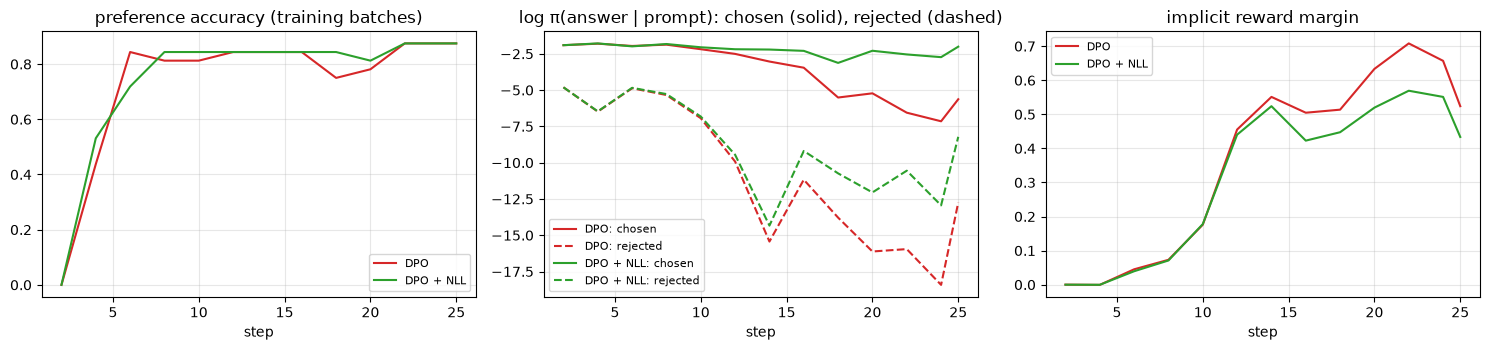

DPO        log π(chosen)   -1.91 ->   -5.63 | log π(rejected)   -4.81 ->  -12.74
DPO + NLL  log π(chosen)   -1.91 ->   -2.01 | log π(rejected)   -4.81 ->   -8.22


In [7]:
dpo("DPO + NLL", loss_type=["sigmoid", "sft"], loss_weights=[1.0, 1.0])

def series(name, key):
    rows = [h for h in RUNS[name]["logs"] if key in h]
    return [h["step"] for h in rows], [h[key] for h in rows]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for name, c in [("DPO", "tab:red"), ("DPO + NLL", "tab:green")]:
    ax[0].plot(*series(name, "rewards/accuracies"), c=c, label=name)
    ax[1].plot(*series(name, "logps/chosen"), c=c, label=f"{name}: chosen")
    ax[1].plot(*series(name, "logps/rejected"), c=c, ls="--", label=f"{name}: rejected")
    ax[2].plot(*series(name, "rewards/margins"), c=c, label=name)
ax[0].set_title("preference accuracy (training batches)"); ax[1].set_title("log π(answer | prompt): chosen (solid), rejected (dashed)")
ax[2].set_title("implicit reward margin")
for a in ax: a.set_xlabel("step"); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
for name in ["DPO", "DPO + NLL"]:
    _, ch = series(name, "logps/chosen"); _, rj = series(name, "logps/rejected")
    print(f"{name:10s} log π(chosen) {ch[0]:7.2f} -> {ch[-1]:7.2f} | log π(rejected) {rj[0]:7.2f} -> {rj[-1]:7.2f}")

**What happened.** Both runs "win" by the trainer's own metrics: preference accuracy on the training batches climbs to about 0.85 and the margin grows. But the middle plot tells two different stories.
- **Plain DPO**: the log-probability of the *correct* answer falls from −1.91 to −5.63. The right JSON becomes about 40× less likely (e^3.7), while the rejected one falls even faster (−4.81 → −12.74). The probability mass goes to answers that are in neither set, and the held-out results collapse: exact match 30 % → 7.5 %, time 30 % → 10 %, and 2 of 40 replies are no longer valid JSON. This is likelihood displacement.
- **DPO + NLL**: the chosen log-probability stays where it was (−1.91 → −2.01) while the rejected one is still pushed down (−4.81 → −8.22). That is the behaviour we wanted, and nothing breaks.

The honest part: DPO + NLL moved exact match only from 30 % to 32.5 %, which is one request out of 40 and within noise. Our pairs mostly say "this time is right, that time is wrong" for individual cases, while what the model lacks is the *rule* (12-hour → 24-hour). 400 pairs and one epoch are not enough to teach it, and more SFT data was the stronger lever in notebook 07. Preference tuning earns its keep where good answers are easier to *recognize* than to *write*: tone, helpfulness, safety, choosing between plausible solutions.

## 4. GRPO: RL with a verifiable reward

DPO needs pairs that someone labelled. GRPO only needs a **checker**: for math, compare the final number; for code, run the unit tests. That is why it powers today's reasoning models.

We switch to a task where answers are easy to verify and the model has to explore: **two-digit addition and subtraction** ("What is 47 + 38?"), starting from the instruct model itself. The system prompt asks for the number only, but the verifier is lenient, as in math RL: it reads the **last** number of the reply, so the model may reason first. With `GRPOTrainer`, reward functions are plain Python: they receive the sampled `completions` plus any dataset column (here `answer`) and return one float per completion.

**Reward design is most of the work.**
- *Sparse*: 1 if the number is exactly right, else 0. Honest, but when all G samples of a prompt are wrong, every advantage is 0 and that prompt teaches nothing.
- *Dense*: partial credit for being close (up to 0.8) + 0.2 for replying with just a number. Every sample gets a signal, but now "close but wrong" also pays, and the format bonus rewards *not* reasoning: the reward is a **proxy** for what we actually want.

To compare the two fairly, both runs compute both rewards, but only one of them drives the update (`reward_weights=[1, 0]` or `[0, 1]`). So we can watch the exact-match rate even in the run that optimizes the dense reward.

**Reward design in theory.** The policy gradient pushes up whatever the reward pays for, in proportion to how often the policy produces it. Three properties of a reward function follow from the GRPO formula.
- **Variance within a group is what teaches.** The advantage is reward minus the group mean. A reward that is almost always 0 (too hard) or almost always 1 (too easy) produces groups with zero variance, hence no gradient. A dense reward spreads the scores and so creates variance on more prompts; that is its whole benefit.
- **The optimum of the reward is what you get, not what you meant.** Goodhart's law ("when a measure becomes a target, it ceases to be a good measure") is the informal statement; Skalse et al. (2022, *Defining and Characterizing Reward Hacking*) give a formal one. Every term of a shaped reward is a behaviour you are paying for: here, closeness pays for near misses and the format bonus pays for short answers.
- **Verifiers have false positives.** A checker that reads the last number accepts a reply whose reasoning is wrong but whose final number is right, and a reply that lists several candidate numbers and happens to end with the right one. With enough samples the policy finds such holes. Strict, well-tested checkers matter more than clever shaping.

In [8]:
MATH_SYSTEM = "Answer with the number only."

def arithmetic_problems(n, seed):
    rng = random.Random(seed); rows = []
    for _ in range(n):
        a, b, op = rng.randint(10, 99), rng.randint(10, 99), rng.choice("+-")
        rows.append({"prompt": [{"role": "system", "content": MATH_SYSTEM}, {"role": "user", "content": f"What is {a} {op} {b}?"}],
                     "answer": a + b if op == "+" else a - b})
    return rows

def extract_number(text):
    """The last integer in the reply: the model may reason first, as long as it ends with the answer."""
    m = re.findall(r"-?\d+", text)
    return int(m[-1]) if m else None

def _text(c):                      # TRL passes conversational completions as [{"role": "assistant", "content": ...}]
    return c[0]["content"] if isinstance(c, list) else c

def reward_exact(completions, answer, **kwargs):
    """Sparse: 1 if the last number in the reply is the right answer."""
    return [1.0 if extract_number(_text(c)) == a else 0.0 for c, a in zip(completions, answer)]

def reward_partial(completions, answer, **kwargs):
    """Dense: up to 0.8 for being close (linear, 0 at a distance of 20 or more) + 0.2 for a bare number."""
    out = []
    for c, a in zip(completions, answer):
        text = _text(c).strip(); pred = extract_number(text)
        out.append(0.0 if pred is None else 0.8 * max(0.0, 1 - abs(pred - a) / 20) + (0.2 if re.fullmatch(r"-?\d+\.?", text) else 0.0))
    return out

math_train = Dataset.from_list(arithmetic_problems(2000, seed=0))
math_test = arithmetic_problems(100, seed=999)

def eval_math(model, name):
    replies = generate(model, tok, [r["prompt"] for r in math_test], max_new_tokens=32, batch_size=50)
    ans = [r["answer"] for r in math_test]
    MATH[name] = {"exact": np.mean(reward_exact(replies, ans)), "partial": np.mean(reward_partial(replies, ans)),
                  "abs_err": np.median([abs(extract_number(r) - a) if extract_number(r) is not None else 99 for r, a in zip(replies, ans)])}
    print(f"{name:22s} exact {100*MATH[name]['exact']:5.1f}% | mean dense reward {MATH[name]['partial']:.3f} | "
          f"median |error| {MATH[name]['abs_err']:.0f}   e.g. {math_test[0]['prompt'][1]['content']} -> {replies[0]!r}")

MATH = {}
del sft_model; free()
math_base = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
eval_math(math_base, "instruct (no RL)")
BASE_STATE = {k: v.detach().cpu().clone() for k, v in math_base.state_dict().items()}

instruct (no RL)       exact   5.0% | mean dense reward 0.090 | median |error| 46   e.g. What is 96 - 20? -> 'To find 96 - 20, we need to subtract 20 from 96, which gives us 94.'


`GRPOConfig` essentials: `num_generations` (the group size G), `max_completion_length`, `temperature` (we need diverse samples, so 1.0), `beta` (KL coefficient; TRL's default is 0, we use 0.04 as in DeepSeekMath so we can watch the KL), and the batch size, which counts **completions**: 8 per micro-batch × 4 accumulation steps = 32 completions = 4 prompts × 8 samples per optimizer step. Rollouts are generated with `model.generate`; at scale you would set `use_vllm=True`, because sampling is the bottleneck of RL.

How these settings map to the objective in the Background section:

| setting | symbol | effect |
|---|---|---|
| `num_generations` | $G$ | larger groups give a better baseline estimate and fewer zero-variance groups, at linear sampling cost |
| `temperature` | | the exploration knob: too low and the $G$ samples are identical (no variance), too high and they are noise |
| `beta` | $\beta$ | strength of the KL leash; 0 removes the reference model entirely (a common choice in recent reasoning work, which relies on clipping and a small learning rate instead) |
| `epsilon` | $\epsilon$ | PPO clip range; only active when a batch of samples is reused for several updates (`num_iterations > 1`) |
| `loss_type`, `scale_rewards` | | the normalization variants (GRPO, DAPO, Dr. GRPO) discussed above |

With one gradient step per batch of samples, as here (TRL's default `num_iterations=1`), the ratio $\rho$ is 1 and GRPO is a group-baselined REINFORCE with a KL penalty.

In [9]:
GRPO_STEPS, GRPO_LR = 40, 1e-4

def grpo(name, weights):
    math_base.load_state_dict(BASE_STATE)
    cfg = GRPOConfig(num_generations=8, max_completion_length=32, temperature=1.0, beta=0.04, learning_rate=GRPO_LR,
                     max_steps=GRPO_STEPS, lr_scheduler_type="constant", reward_weights=weights, **common(8, 4))
    trainer = GRPOTrainer(model=math_base, reward_funcs=[reward_exact, reward_partial], args=cfg,
                          train_dataset=math_train, processing_class=tok, peft_config=lora())
    model = run(trainer, name)
    eval_math(model, name)
    del trainer; free()

grpo("GRPO sparse (exact)", weights=[1.0, 0.0])
grpo("GRPO dense (partial)", weights=[0.0, 1.0])

GRPO sparse (exact): 40 steps, 200 s, peak VRAM 0.88 GB


GRPO sparse (exact)    exact  46.0% | mean dense reward 0.553 | median |error| 2   e.g. What is 96 - 20? -> '96 - 20 = 84.'


GRPO dense (partial): 40 steps, 194 s, peak VRAM 0.88 GB


GRPO dense (partial)   exact  42.0% | mean dense reward 0.566 | median |error| 2   e.g. What is 96 - 20? -> '96 - 20 = 84.'


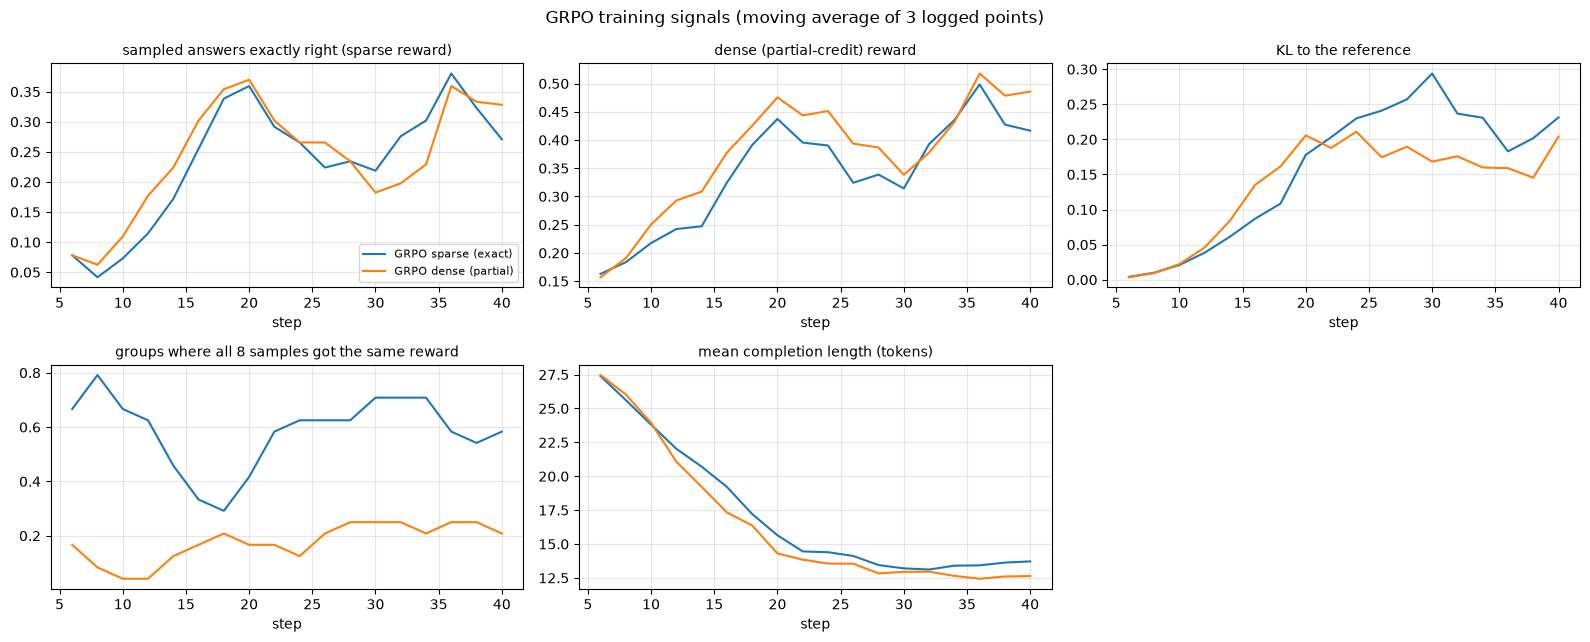

In [10]:
def smooth(v, k=3):
    v = np.asarray(v, dtype=float); return np.convolve(v, np.ones(k) / k, mode="valid") if len(v) >= k else v

keys = ["rewards/reward_exact/mean", "rewards/reward_partial/mean", "kl", "frac_reward_zero_std", "completions/mean_length"]
titles = ["sampled answers exactly right (sparse reward)", "dense (partial-credit) reward", "KL to the reference",
          "groups where all 8 samples got the same reward", "mean completion length (tokens)"]
fig, axes = plt.subplots(2, 3, figsize=(16, 6.5)); axes = axes.flatten(); axes[-1].axis("off")
for name, c in [("GRPO sparse (exact)", "tab:blue"), ("GRPO dense (partial)", "tab:orange")]:
    for a, key in zip(axes, keys):
        steps, vals = series(name, key)
        a.plot(steps[len(steps) - len(smooth(vals)):], smooth(vals), c=c, label=name)
for a, t in zip(axes, titles):
    a.set_title(t, fontsize=10); a.set_xlabel("step"); a.grid(alpha=.3)
axes[0].legend(fontsize=8); fig.suptitle("GRPO training signals (moving average of 3 logged points)"); plt.tight_layout(); plt.show()

**What happened.**
- The instruct model starts at 5 %. It explains instead of answering, often runs out of its 32 tokens, and makes subtraction slips ("96 − 20 … gives us 94").
- After only 40 GRPO steps (160 prompts, 1,280 sampled answers, no labels, about 3.5 minutes) it reaches **46 %** with the sparse reward and **42 %** with the dense one. The median error drops from 46 to 2.
- The **completion length** falls from ~27 to ~13 tokens in both runs: the policy discovered that a short `96 - 20 = …` answer gets rewarded more often than a long explanation that gets cut off. Nobody wrote that rule; it emerged from the reward. Wrong answers remain (the example is still off by 8), but now they are close.
- **Sparse vs dense, the signal**: with the exact reward, most of the time 60–80 % of the groups (less around step 18) have all 8 samples scored the same (usually all wrong), so they contribute no gradient. With the dense reward this drops to ~5–25 %, and the exact-match rate of the samples rises faster in the first 15 steps.
- **Sparse vs dense, the outcome**: on held-out problems the dense run scores slightly *higher* on its own proxy (0.566 vs 0.553) and slightly *lower* on exact match (42 % vs 46 %). That is the direction Goodhart's law predicts, but 4 problems out of 100 is within noise, so we cannot claim it from this run. What we can say: the denser signal did not buy a better final model here.
- **KL** to the reference grows to ~0.2–0.3 nats per token: the policy changed its style a lot, as expected. In longer runs a KL that keeps climbing while the held-out metric stalls is the classic sign of reward hacking.

## 5. Evaluation

Booking extraction (40 held-out requests):
   SFT          valid 100.0% | exact  30.0% | fields  86.0% | time  30.0%
   DPO          valid  95.0% | exact   7.5% | fields  77.5% | time  10.0% |   62 s, peak 1.40 GB
   DPO + NLL    valid 100.0% | exact  32.5% | fields  86.5% | time  32.5% |   62 s, peak 1.40 GB
Arithmetic (100 held-out problems):
   instruct (no RL)       exact   5.0% | dense reward 0.090 | median |error| 46
   GRPO sparse (exact)    exact  46.0% | dense reward 0.553 | median |error| 2 |  200 s, peak 0.88 GB
   GRPO dense (partial)   exact  42.0% | dense reward 0.566 | median |error| 2 |  194 s, peak 0.88 GB


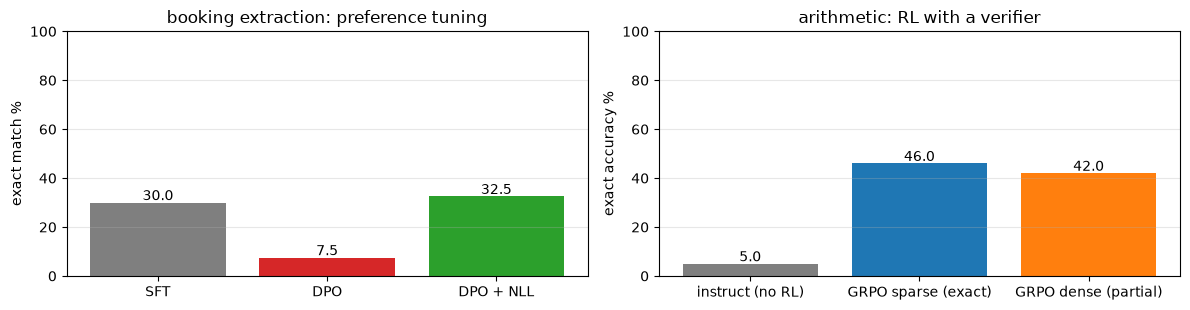

In [11]:
print("Booking extraction (40 held-out requests):")
for n in ["SFT", "DPO", "DPO + NLL"]:
    r = RESULTS[n]
    print(f"   {n:12s} valid {100*r['valid']:5.1f}% | exact {100*r['exact']:5.1f}% | fields {100*r['fields']:5.1f}% | time {100*r['time']:5.1f}%"
          + (f" | {RUNS[n]['time']:4.0f} s, peak {RUNS[n]['peak']:.2f} GB" if n in RUNS else ""))
print("Arithmetic (100 held-out problems):")
for n, r in MATH.items():
    print(f"   {n:22s} exact {100*r['exact']:5.1f}% | dense reward {r['partial']:.3f} | median |error| {r['abs_err']:.0f}"
          + (f" | {RUNS[n]['time']:4.0f} s, peak {RUNS[n]['peak']:.2f} GB" if n in RUNS else ""))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
names = ["SFT", "DPO", "DPO + NLL"]
ax[0].bar(names, [100 * RESULTS[n]["exact"] for n in names], color=["tab:gray", "tab:red", "tab:green"])
ax[0].set_ylabel("exact match %"); ax[0].set_title("booking extraction: preference tuning"); ax[0].set_ylim(0, 100)
names = list(MATH)
ax[1].bar(names, [100 * MATH[n]["exact"] for n in names], color=["tab:gray", "tab:blue", "tab:orange"])
ax[1].set_ylabel("exact accuracy %"); ax[1].set_title("arithmetic: RL with a verifier"); ax[1].set_ylim(0, 100)
for a in ax:
    a.grid(alpha=.3, axis="y")
    for p in a.patches: a.text(p.get_x() + p.get_width() / 2, p.get_height() + 1, f"{p.get_height():.1f}", ha="center")
plt.tight_layout(); plt.show()

**Reading the comparison.**
- **Preference tuning** (booking task): plain DPO *hurt* the model (30 % → 7.5 %) while its training metrics looked good. DPO + NLL was safe (32.5 %) but brought no real gain on a task where the model lacks a rule rather than a preference.
- **RL with a verifier** (arithmetic): GRPO took the model from 5 % to 42–46 % in about 3.5 minutes, without a single labelled answer, just a checker and sampling. With this budget the sparse reward was as good as the dense one on the metric that matters.
- Peak VRAM was at most 1.4 GB for everything: LoRA adapters make the reference model free (adapter off = reference), which is why DPO and GRPO fit next to Ollama on a 6 GB laptop GPU.

Small test sets (40 and 100 items) mean differences of a few points are noise; the large effects (DPO's collapse, GRPO's 5 % → 40+ %) are not.

## Takeaways

- **DPO** turns (chosen, rejected) pairs into a classification loss on implicit rewards: no reward model, no sampling. The best pairs are your model's own mistakes.
- **Watch the chosen log-probability**, not just preference accuracy: plain DPO can win the comparison while making the good answer less likely. Adding the SFT loss on the chosen answer (`loss_type=["sigmoid", "sft"]` in TRL 1.x, formerly `rpo_alpha`) is a cheap, robust default.
- **GRPO** needs only prompts and a verifier. The group-relative advantage replaces the critic, and the reward function *is* the specification: a dense reward learns from every sample but optimizes a proxy (Goodhart's law), so always evaluate on the metric you care about.
- Diagnose RL with the reward curves, the KL to the reference, and the fraction of groups with zero reward variance (they carry no gradient).
- At scale: `DPOTrainer` with a learning rate around 5e-7 to 5e-6 for full fine-tuning; `GRPOTrainer(use_vllm=True, num_generations=8–16)` with reasoning-length completions. Read: DPO (Rafailov 2023), DeepSeekMath (GRPO), DeepSeek-R1, DAPO and Dr. GRPO (the loss variants TRL offers as `loss_type`).

## Results

| question | measured | lesson |
|---|---|---|
| does plain DPO improve the SFT model? | exact match 30.0 % → 7.5 % on 40 held-out bookings; log-prob of the chosen answer -1.91 → -5.63 | DPO can win the comparison while making the good answer less likely |
| does adding the SFT (NLL) loss fix it? | exact match 32.5 %; chosen log-prob -1.91 → -2.01 | a cheap, safe default, but no real gain when the model lacks a rule |
| can RL with only a verifier teach arithmetic? | GRPO: exact 5.0 % → 46.0 % (sparse reward) and 42.0 % (dense) on 100 problems, about 200 s per run | a checker plus sampling replaces labelled answers |
| sparse or dense reward? | 46.0 % vs 42.0 % exact; median absolute error 46 → 2 for both | the dense reward is a proxy; judge it on the real metric |
| memory | peak VRAM 1.40 GB (DPO), 0.88 GB (GRPO) | with LoRA the reference model is free |

## In production

**Where these methods sit today.**
- The usual open post-training recipe is SFT, then preference optimization (DPO or a variant such as SimPO, KTO or ORPO), then RL with verifiable rewards for math, code and tool use.
- Reasoning models are trained mostly with GRPO-style RL against verifiers: unit tests, math checkers, format and length checks. Preference data for the "soft" qualities comes from human raters or an LLM judge, increasingly sampled on-policy from the current model.

**Tools.**
- TRL (`DPOTrainer`, `GRPOTrainer`) and Unsloth for one GPU; verl, OpenRLHF and NeMo-RL for multi-node runs.
- vLLM or SGLang generate the rollouts, which are most of the cost of RL.

**Failure modes.**
- Reward hacking: the policy finds the gap in the verifier (output format tricks, special-casing tests).
- Likelihood displacement in DPO, as measured here; off-policy pairs the model would never produce teach little.
- Losing general skills while chasing one metric: keep a broad regression set next to the target metric and watch the KL to the reference.
- Groups with zero reward variance carry no gradient: prompts that are always solved or never solved are wasted compute.
- Small evaluation sets: a few points of difference on 40 or 100 items is noise.

**Next:** `20_reasoning_test_time_compute.ipynb`, which spends the compute at inference time instead of training time, then `09_quantization.ipynb`.